# 03 · Interventions

Conditioning asks "what do we expect to see, given that X = x?".  An
intervention asks "what happens if we *set* X = x?".  When X and the outcome
share a cause, the two answers differ.  NBN answers both from the same model,
learned from observational data only, because the graph says where the
confounder is.

- **NBN API:** `query(..., do=...)`, `query_batch(..., do=...)` with one
  intervention per row, `intervene()` (returns the mutilated network), and
  `do=` on every engine (`TensorVariableElimination`,
  `LikelihoodWeightingEngine`, `HybridRouter`, `AmortizedISEngine`,
  `AmortizedVIEngine`).
- **Runtime:** under 10 s on a laptop CPU.
- **Install:** `pip install "nbn[examples]"`, then `jupyter lab examples/`.
- **Device:** CUDA or Apple MPS when available, else the CPU (set `NBN_EXAMPLES_DEVICE=cpu` to force the CPU).

Two ground-truth networks, both with a confounder:

1. Discrete: `Rain -> Sprinkler`, `(Rain, Sprinkler) -> WetGrass`.  People
   rarely turn the sprinkler on when it rains, so `Rain` confounds
   `Sprinkler -> WetGrass`.
2. Hybrid: `Severity -> Dose`, `(Severity, Dose) -> Recovery`.  Severe
   patients get higher doses and recover less often, so `Severity` confounds
   `Dose -> Recovery`.

The true interventional answers come from the adjustment formula,
`P(y | do(x)) = sum_z P(z) P(y | x, z)`.

In [1]:
import math
import os

import matplotlib.pyplot as plt
import numpy as np
import torch

from nbn import (
    CategoricalTableMechanism,
    HybridRouter,
    LikelihoodWeightingEngine,
    LinearGaussianMechanism,
    NeuralBayesianNetwork,
    NeuralCategoricalMechanism,
    TensorVariableElimination,
    seed_all,
)
from nbn.inference.amortized_is import AmortizedISEngine
from nbn.inference.amortized_vi import AmortizedVIEngine
from nbn.utils.device import resolve_device

# "auto" picks CUDA, then Apple MPS, then the CPU.  The stored outputs were made
# with NBN_EXAMPLES_DEVICE=cpu; on an accelerator the last digits can differ.
device = resolve_device(os.environ.get("NBN_EXAMPLES_DEVICE", "auto"))
print("device:", device)

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
GREY, INK = "#a3a29c", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
                     "font.size": 9})


def to_numpy(t: torch.Tensor):
    """Move to the CPU first, then convert: tensors on MPS / CUDA cannot go to numpy directly."""
    return t.detach().cpu().numpy()

device: cpu


## 1. The discrete network: seeing vs doing

We fit tables on 20,000 observational rows and compare
`P(WetGrass = 1 | Sprinkler = s)` (conditioning) with
`P(WetGrass = 1 | do(Sprinkler = s))` (intervention).

In [2]:
P_RAIN = torch.tensor([0.7, 0.3])
P_SPRINKLER = torch.tensor([[0.5, 0.5], [0.9, 0.1]])               # [rain, sprinkler]
P_WET = torch.tensor([[[0.95, 0.05], [0.20, 0.80]],                # [rain, sprinkler, wet]
                      [[0.15, 0.85], [0.02, 0.98]]])
EDGES = [("Rain", "Sprinkler"), ("Rain", "WetGrass"), ("Sprinkler", "WetGrass")]


def sample(n: int) -> dict:
    rain = torch.multinomial(P_RAIN, n, replacement=True)
    sprinkler = torch.bernoulli(P_SPRINKLER[rain, 1]).long()
    wet = torch.bernoulli(P_WET[rain, sprinkler, 1]).long()
    return {"Rain": rain, "Sprinkler": sprinkler, "WetGrass": wet}


def true_conditional(s: int) -> float:
    """P(WetGrass = 1 | Sprinkler = s): Rain is reweighted by what the sprinkler reveals."""
    joint = P_RAIN * P_SPRINKLER[:, s] * P_WET[:, s, 1]
    return float(joint.sum() / (P_RAIN * P_SPRINKLER[:, s]).sum())


def true_do(s: int) -> float:
    """P(WetGrass = 1 | do(Sprinkler = s)) = sum_r P(r) P(WetGrass = 1 | r, s)."""
    return float((P_RAIN * P_WET[:, s, 1]).sum())


seed_all(0)
disc = NeuralBayesianNetwork(EDGES, dict.fromkeys(("Rain", "Sprinkler", "WetGrass"), ("discrete", 2)),
                             device=device)
disc.auto_mechanisms()
disc.fit(sample(20_000))

rows = {}
for s in (0, 1):
    rows[s] = {"seen (NBN)": float(disc.query(["WetGrass"], {"Sprinkler": s})[1]),
               "seen (truth)": true_conditional(s),
               "do (NBN)": float(disc.query(["WetGrass"], do={"Sprinkler": s})[1]),
               "do (truth)": true_do(s)}
    print(f"Sprinkler = {s}:  " + "   ".join(f"{k} {v:.3f}" for k, v in rows[s].items()))
effect_seen = rows[1]["seen (NBN)"] - rows[0]["seen (NBN)"]
effect_do = rows[1]["do (NBN)"] - rows[0]["do (NBN)"]
print(f"\nNBN: difference when the sprinkler is on, seen {effect_seen:+.3f}, do {effect_do:+.3f}")
print(f"truth:                                 seen {true_conditional(1) - true_conditional(0):+.3f}, "
      f"do {true_do(1) - true_do(0):+.3f}")

Sprinkler = 0:  seen (NBN) 0.403   seen (truth) 0.398   do (NBN) 0.294   do (truth) 0.290
Sprinkler = 1:  seen (NBN) 0.816   seen (truth) 0.814   do (NBN) 0.855   do (truth) 0.854

NBN: difference when the sprinkler is on, seen +0.413, do +0.562
truth:                                 seen +0.416, do +0.564


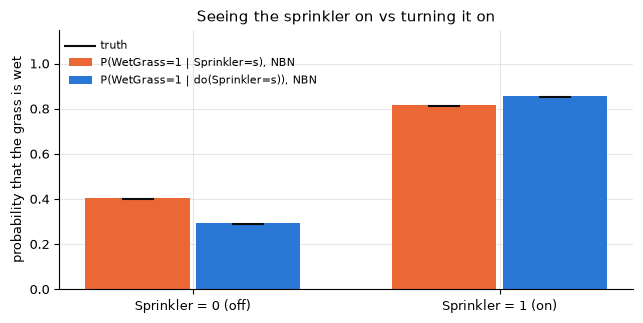

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 3.3))
x = np.arange(2)
for k, (key, color, label) in enumerate((("seen", ORANGE, "P(WetGrass=1 | Sprinkler=s)"),
                                        ("do", BLUE, "P(WetGrass=1 | do(Sprinkler=s))"))):
    vals = [rows[s][f"{key} (NBN)"] for s in (0, 1)]
    ax.bar(x + (k - 0.5) * 0.36, vals, 0.34, color=color, label=label + ", NBN")
    ax.scatter(x + (k - 0.5) * 0.36, [rows[s][f"{key} (truth)"] for s in (0, 1)], marker="_",
               s=500, color=INK, zorder=3, label="truth" if k == 0 else None)
ax.set_xticks(x, ["Sprinkler = 0 (off)", "Sprinkler = 1 (on)"])
ax.set(ylabel="probability that the grass is wet", ylim=(0, 1.15),
       title="Seeing the sprinkler on vs turning it on")
ax.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

Seeing the sprinkler on raises the chance of wet grass by 0.413; turning it on
raises it by 0.562 (truth: 0.416 and 0.564).  A sprinkler that is *seen* on is
also a sign that it is not raining, and that hides part of its effect.  A
sprinkler seen off has the opposite effect: it makes rain more likely, so
`P(wet | seen off)` = 0.403 is above `P(wet | do(off))` = 0.294.  NBN learned
from observations only, and its interventional answers are within 0.004 of the
adjustment formula.

`do=` and `evidence=` combine.  Given that the grass is wet, was it raining?
If we *saw* the sprinkler on, rain becomes less likely (the sprinkler explains
the wet grass, and it is rarely on when it rains).  If we *turned* it on
ourselves, the sprinkler says nothing about the weather.

In [4]:
def true_rain_given(wet: int, s: int, intervened: bool) -> float:
    prior = P_RAIN if intervened else P_RAIN * P_SPRINKLER[:, s]
    post = prior * P_WET[:, s, wet]
    return float(post[1] / post.sum())


print(f"P(Rain=1 | WetGrass=1)                  NBN {float(disc.query(['Rain'], {'WetGrass': 1})[1]):.3f}")
print(f"P(Rain=1 | WetGrass=1, Sprinkler=1)     NBN "
      f"{float(disc.query(['Rain'], {'WetGrass': 1, 'Sprinkler': 1})[1]):.3f}   truth "
      f"{true_rain_given(1, 1, intervened=False):.3f}")
print(f"P(Rain=1 | WetGrass=1, do(Sprinkler=1)) NBN "
      f"{float(disc.query(['Rain'], {'WetGrass': 1}, do={'Sprinkler': 1})[1]):.3f}   truth "
      f"{true_rain_given(1, 1, intervened=True):.3f}")

P(Rain=1 | WetGrass=1)                  NBN 0.468
P(Rain=1 | WetGrass=1, Sprinkler=1)     NBN 0.094   truth 0.095
P(Rain=1 | WetGrass=1, do(Sprinkler=1)) NBN 0.347   truth 0.344


Without the sprinkler, wet grass makes rain likely (0.468).  Seeing the
sprinkler on drops it to 0.094: the sprinkler explains the wet grass, and it is
rarely on in the rain.  Turning the sprinkler on ourselves gives 0.347
(truth 0.344): it still explains part of the wet grass, but it carries no
information about the weather.

## 2. `intervene()`: the mutilated network

`intervene(do)` returns a new model in which the edges into the intervened
node are cut and its mechanism is a point mass (`DeterministicMechanism` for a
discrete node, `DiracGaussianMechanism` for a continuous one).  The original
model is not changed.  Querying the mutilated model without `do=` gives the
same answer as `query(..., do=...)` on the original.

In [5]:
cut = disc.intervene({"Sprinkler": 1})
print("original edges:  ", disc.dag.edges())
print("mutilated edges: ", cut.dag.edges())
print("Sprinkler mechanism:", type(cut.mechanisms["Sprinkler"]).__name__,
      "| original still has", type(disc.mechanisms["Sprinkler"]).__name__)
a = cut.query(["WetGrass"])
b = disc.query(["WetGrass"], do={"Sprinkler": 1})
print(f"P(WetGrass=1): mutilated model {float(a[1]):.6f}, do= on the original {float(b[1]):.6f}")
seed_all(1)
draws = cut.sample(10_000)
print(f"10,000 samples of the mutilated model: Sprinkler always 1? {bool((draws['Sprinkler'] == 1).all())}; "
      f"share of wet grass {float(draws['WetGrass'].float().mean()):.3f}")

original edges:   [('Rain', 'Sprinkler'), ('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')]
mutilated edges:  [('Rain', 'WetGrass'), ('Sprinkler', 'WetGrass')]
Sprinkler mechanism: DeterministicMechanism | original still has CategoricalTableMechanism
P(WetGrass=1): mutilated model 0.855375, do= on the original 0.855375
10,000 samples of the mutilated model: Sprinkler always 1? True; share of wet grass 0.856


## 3. A continuous treatment: dose-response in one batched call

Ground truth of the hybrid network:

    Severity ~ Bernoulli(0.4)
    Dose     | Severity ~ N(1 + 2 Severity, 0.6^2)
    Recovery | Dose, Severity ~ Bernoulli(sigmoid(0.5 + 0.8 Dose - 3.5 Severity))

A higher dose helps every patient, but severe patients get higher doses and
recover less often.  We fit a linear-Gaussian `Dose` (the true family) and a
neural categorical `Recovery` (it takes a continuous and a discrete parent) on
20,000 observational rows.

`query_batch` takes one intervention value per row, so the whole curve
`P(Recovery = 1 | do(Dose = x))` for 61 doses is a single call with
`do={"Dose": x_grid}`.  The conditional curve is a single call too, with the
doses as evidence.

In [6]:
P_SEVERE = 0.4


def logistic(t):
    return 1 / (1 + torch.exp(-t))


def h_sample(n: int) -> dict:
    severity = torch.bernoulli(torch.full((n,), P_SEVERE)).long()
    dose = 1 + 2 * severity + 0.6 * torch.randn(n)
    recovery = torch.bernoulli(logistic(0.5 + 0.8 * dose - 3.5 * severity)).long()
    return {"Severity": severity, "Dose": dose[:, None], "Recovery": recovery}


def normal_pdf(x, mean, std):
    return torch.exp(-0.5 * ((x - mean) / std) ** 2) / (std * math.sqrt(2 * math.pi))


def true_curves(x: torch.Tensor):
    pz = torch.tensor([1 - P_SEVERE, P_SEVERE])
    p_y = torch.stack([logistic(0.5 + 0.8 * x - 3.5 * z) for z in (0, 1)])        # [2, B]
    p_do = (pz[:, None] * p_y).sum(0)                                                # adjustment
    post_z = pz[:, None] * torch.stack([normal_pdf(x, 1 + 2 * z, 0.6) for z in (0, 1)])
    p_seen = (post_z * p_y).sum(0) / post_z.sum(0)
    return p_seen, p_do


seed_all(2)
hyb = NeuralBayesianNetwork([("Severity", "Dose"), ("Severity", "Recovery"), ("Dose", "Recovery")],
                            {"Severity": ("discrete", 2), "Dose": ("continuous", 1),
                             "Recovery": ("discrete", 2)}, device=device)
hyb.set_mechanism("Severity", CategoricalTableMechanism())
hyb.set_mechanism("Dose", LinearGaussianMechanism())
hyb.set_mechanism("Recovery", NeuralCategoricalMechanism(n_classes=2))
hyb.fit(h_sample(20_000), consolidate=False)

x_grid = torch.linspace(-0.5, 4.5, 61)
seed_all(3)
out_do = hyb.query_batch(["Recovery"], {}, do={"Dose": x_grid[:, None]}, n_samples=4096)
out_seen = hyb.query_batch(["Recovery"], {"Dose": x_grid[:, None]}, n_samples=4096)
print("do values:", tuple(x_grid[:, None].shape), "-> answers:", tuple(out_do.shape))
p_do, p_seen = out_do[:, 1].cpu(), out_seen[:, 1].cpu()
t_seen, t_do = true_curves(x_grid)
print(f"do curve:   mean |NBN - truth| {float((p_do - t_do).abs().mean()):.3f}")
print(f"seen curve: mean |NBN - truth| {float((p_seen - t_seen).abs().mean()):.3f}")
for x0 in (1.0, 2.0, 3.0):
    i = int((x_grid - x0).abs().argmin())
    print(f"Dose = {x0}:  seen {float(p_seen[i]):.3f} (truth {float(t_seen[i]):.3f})   "
          f"do {float(p_do[i]):.3f} (truth {float(t_do[i]):.3f})")

do values: (61, 1) -> answers: (61, 2)
do curve:   mean |NBN - truth| 0.011
seen curve: mean |NBN - truth| 0.010
Dose = 1.0:  seen 0.783 (truth 0.784)   do 0.521 (truth 0.511)
Dose = 2.0:  seen 0.628 (truth 0.614)   do 0.616 (truth 0.614)
Dose = 3.0:  seen 0.345 (truth 0.358)   do 0.713 (truth 0.710)


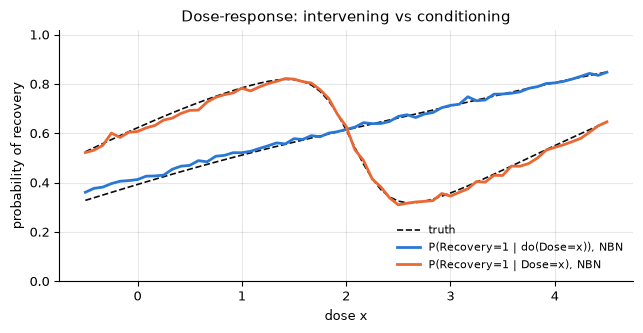

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(to_numpy(x_grid), to_numpy(t_do), color=INK, lw=1.2, ls="--", label="truth")
ax.plot(to_numpy(x_grid), to_numpy(t_seen), color=INK, lw=1.2, ls="--")
ax.plot(to_numpy(x_grid), to_numpy(p_do), color=BLUE, lw=2, label="P(Recovery=1 | do(Dose=x)), NBN")
ax.plot(to_numpy(x_grid), to_numpy(p_seen), color=ORANGE, lw=2, label="P(Recovery=1 | Dose=x), NBN")
ax.set(xlabel="dose x", ylabel="probability of recovery", ylim=(0, 1.02),
       title="Dose-response: intervening vs conditioning")
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

The intervention curve (blue) rises with the dose: for every patient, more
dose helps.  The conditional curve (orange) falls between doses of about 1.5
and 2.5, because the patients seen there are mostly severe ones.  At dose 3,
conditioning gives 0.345 and intervening gives 0.713 (truth 0.358 and 0.710).
Read causally, the conditional curve would suggest that high doses hurt.  Both
NBN curves are within 0.011 of the truth on average; the wiggles are
Monte-Carlo noise from 4096 particles per dose.

## 4. `do=` works on every engine

The same two interventional queries on the discrete network, answered by each
engine; the sampling engines all use 8192 particles.  The model was learned
from data, so even exact VE differs a little from the truth.  The amortized engines are trained once on the model;
an intervention changes the model, so `AmortizedVIEngine` answers `do=`
queries with its built-in likelihood-weighting engine, and
`AmortizedISEngine` runs its proposal on the intervened network.

In [8]:
seed_all(4)
ais = AmortizedISEngine(n_samples=8192)
ais.train_proposal(disc)
seed_all(4)
avi = AmortizedVIEngine(n_samples=8192)
avi.train_proposal(disc)
engines = {"TensorVariableElimination": TensorVariableElimination(),
           "LikelihoodWeightingEngine": LikelihoodWeightingEngine(n_samples=8192),
           "HybridRouter": HybridRouter(n_samples=8192),
           "AmortizedISEngine": ais,
           "AmortizedVIEngine": avi}
queries = {"P(WetGrass=1 | do(Sprinkler=1))": (["WetGrass"], {}, true_do(1)),
           "P(Rain=1 | WetGrass=1, do(Sprinkler=1))": (["Rain"], {"WetGrass": 1},
                                                       true_rain_given(1, 1, intervened=True))}
answers = {}
seed_all(5)
for name, eng in engines.items():
    answers[name] = [float(disc.query(t, ev, engine=eng, do={"Sprinkler": 1})[1])
                     for t, ev, _ in queries.values()]
print(f"{'engine':27s}" + "".join(f"{q:>42s}" for q in queries))
print(f"{'truth':27s}" + "".join(f"{v[2]:42.4f}" for v in queries.values()))
for name, vals in answers.items():
    print(f"{name:27s}" + "".join(f"{v:42.4f}" for v in vals))

engine                                P(WetGrass=1 | do(Sprinkler=1))   P(Rain=1 | WetGrass=1, do(Sprinkler=1))
truth                                                          0.8540                                    0.3443
TensorVariableElimination                                      0.8554                                    0.3468
LikelihoodWeightingEngine                                      0.8599                                    0.3499
HybridRouter                                                   0.8554                                    0.3468
AmortizedISEngine                                              0.8522                                    0.3441
AmortizedVIEngine                                              0.8607                                    0.3537


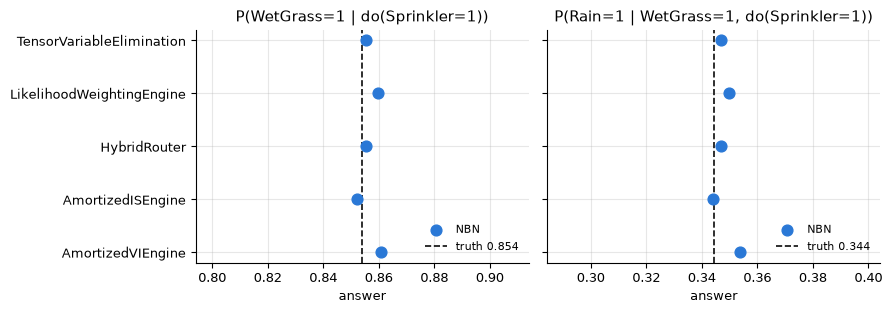

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
y = np.arange(len(engines))
for k, (ax, (qname, (_, _, truth))) in enumerate(zip(axes, queries.items())):
    vals = [answers[e][k] for e in engines]
    ax.scatter(vals, y, s=60, color=BLUE, zorder=3, label="NBN")
    ax.axvline(truth, color=INK, lw=1.2, ls="--", label=f"truth {truth:.3f}")
    ax.set_xlim(truth - 0.06, truth + 0.06)
    ax.set(xlabel="answer", title=qname)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
axes[0].set_yticks(y, list(engines))
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

Every engine is within 0.01 of the truth on both queries.  `HybridRouter`
picked VE here (all nodes are discrete), so its answers equal VE's.  VE's own
small gap is learning error; the other differences are Monte-Carlo noise.